# Predicting historical loan approvals

Can a short application form predict the decision recorded in the case study? The positive label is an approval. The data record neither repayment nor default, so this exercise evaluates agreement with past decisions. The proposed use is to prioritize a human review queue.

[Assigned Kaggle dataset](https://www.kaggle.com/datasets/bhanupratapbiswas/loan-approval-prediction-case-study)

## Load the assigned data
Run the notebook from top to bottom. The first run downloads the public Kaggle ZIP. For offline use, place the same archive at `data/loan-approval-prediction-case-study.zip` beside the notebook.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
from hashlib import sha256

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TEAL, AMBER = "#187c77", "#bd6b32"
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlepad": 12})
slug = 'loan-approval-prediction-case-study'
archive = Path("data") / (slug + ".zip")
if not archive.is_file():
    archive.parent.mkdir(parents=True, exist_ok=True)
    url = "https://api.kaggle.com/v1/datasets/download/bhanupratapbiswas/" + slug
    with urlopen(Request(url, headers={"User-Agent": "Alfido-coursework/1.0"}), timeout=120) as response:
        payload = response.read()
    with ZipFile(BytesIO(payload)) as downloaded:
        assert downloaded.testzip() is None, "Incomplete dataset archive"
    archive.write_bytes(payload)

# Fingerprints identify the exact source tables used for the saved results.
expected = {'loan_prediction.csv': '710e61a2a5bb13a3ac0e808b2e0e780942c2fee4ecc52cb154679495790633b2'}

def read_table(filename):
    with ZipFile(archive) as source:
        content = source.read(filename)
    if sha256(content).hexdigest() != expected[filename]:
        raise ValueError(f"{filename} differs from the snapshot used for this report.")
    return pd.read_csv(BytesIO(content))

def profile(frame):
    return pd.DataFrame({"data_type": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                         "distinct_values": frame.nunique()})

## Audit the application file
The raw rows contain a leading serial number that has no corresponding header. Pandas reads it as the row index. We verify the actual ID and target before splitting the data.

,data_type,missing,distinct_values
Loan_ID,object,0,614
Gender,object,13,2
Married,object,3,2
Dependents,object,15,4
Education,object,0,2
Self_Employed,object,32,2
ApplicantIncome,int64,0,505
CoapplicantIncome,float64,0,287
LoanAmount,float64,22,203
Loan_Amount_Term,float64,14,10


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.0,614.0,592.0,600.0,564.0
mean,5403.5,1621.2,146.4,342.0,0.8
std,6109.0,2926.2,85.6,65.1,0.4
min,150.0,0.0,9.0,12.0,0.0
25%,2877.5,0.0,100.0,360.0,1.0
50%,3812.5,1188.5,128.0,360.0,1.0
75%,5795.0,2297.2,168.0,360.0,1.0
max,81000.0,41667.0,700.0,480.0,1.0


Applications: 614. Approved: 422. Declined: 192.


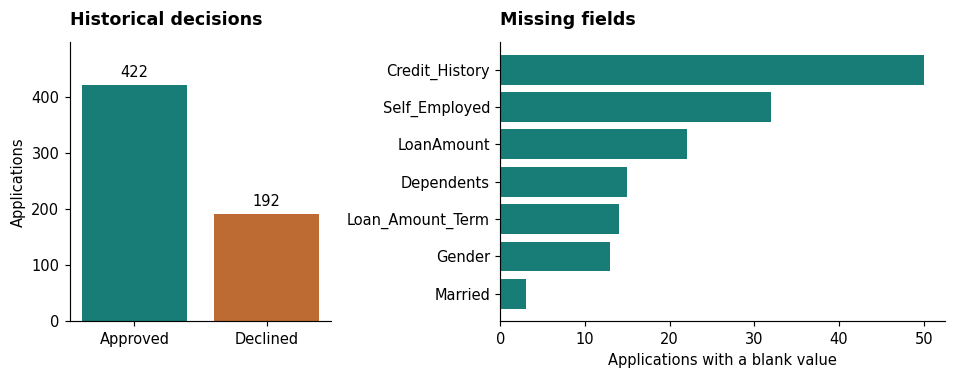

In [2]:
raw = read_table("loan_prediction.csv")
assert raw.Loan_ID.is_unique and raw.Loan_ID.str.fullmatch(r"LP\d+").all()
assert set(raw.Loan_Status) == {"Y", "N"}
display(profile(raw))
display(raw.select_dtypes("number").describe().round(1))
y = raw.Loan_Status.map({"Y": 1, "N": 0})
print(f"Applications: {len(y)}. Approved: {y.sum()}. Declined: {(y==0).sum()}.")
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.7), gridspec_kw={"width_ratios":[1,1.7]})
target_counts = raw.Loan_Status.value_counts().reindex(["Y", "N"])
bars = axes[0].bar(["Approved", "Declined"], target_counts, color=[TEAL, AMBER])
axes[0].bar_label(bars, padding=3)
axes[0].set(title="Historical decisions", ylabel="Applications", ylim=(0, target_counts.max()*1.18))
missing = raw.isna().sum().loc[lambda s: s.gt(0)].sort_values()
axes[1].barh(missing.index, missing, color=TEAL)
axes[1].set(title="Missing fields", xlabel="Applications with a blank value")
fig.tight_layout()
plt.show()

## Keep a final test set separate
Reserve a stratified 20% test set. Median imputation and scaling for numeric features, and mode imputation and one-hot encoding for categories, are fitted inside each training fold. Credit history is a binary category. Omit the serial number, application ID, gender and marital status from the predictors. Omitting demographic fields alone cannot establish fairness.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

numeric = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
categorical = ["Credit_History", "Dependents", "Education", "Self_Employed", "Property_Area"]
X = raw[numeric + categorical]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
preprocess = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("category", make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore")), categorical)
])
models = {
    "Logistic regression": make_pipeline(clone(preprocess), LogisticRegression(
        class_weight="balanced", solver="liblinear", max_iter=2000, random_state=42)),
    "Random forest": make_pipeline(clone(preprocess), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=6, class_weight="balanced", random_state=42, n_jobs=1))
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Development: {len(y_train)} applications. Untouched final test: {len(y_test)}.")

Development: 491 applications. Untouched final test: 123.


## Select a model and a queue threshold on development data
Class weights give the minority class more influence during fitting. Compare out-of-fold ROC-AUC to select a model, with one prediction per training row from a model that did not see that row. Then minimize a hypothetical review cost: sending a historically declined file to the priority queue costs two units, and delaying a historically approved file costs one. The weights are a planning assumption. Break equal-cost ties by selecting the threshold closest to 0.50.

,Precision,Recall,F1,ROC-AUC
Logistic regression,0.793,0.852,0.821,0.718
Random forest,0.786,0.917,0.847,0.756


Selected on development folds: Random forest, threshold 0.47, cost 191.


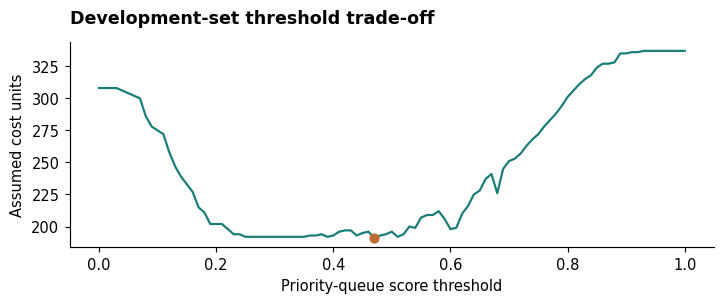

In [4]:
def metrics(actual, scores, threshold):
    pred = scores >= threshold
    return {"Precision": precision_score(actual, pred, zero_division=0),
            "Recall": recall_score(actual, pred), "F1": f1_score(actual, pred),
            "ROC-AUC": roc_auc_score(actual, scores)}

oof = {name: cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
       for name, model in models.items()}
cv_table = pd.DataFrame({name: metrics(y_train, scores, 0.5) for name, scores in oof.items()}).T
display(cv_table.round(3))
chosen = cv_table["ROC-AUC"].idxmax()
rows = []
for threshold in np.arange(0, 101)/100:
    tn, fp, fn, tp = confusion_matrix(y_train, oof[chosen] >= threshold, labels=[0,1]).ravel()
    rows.append((threshold, fp, fn, 2*fp + fn))
costs = pd.DataFrame(rows, columns=["threshold", "FP", "FN", "cost"])
costs["distance"] = (costs.threshold - .5).abs().round(4)
pick = costs.sort_values(["cost", "distance", "threshold"]).iloc[0]
threshold = float(pick.threshold)
print(f"Selected on development folds: {chosen}, threshold {threshold:.2f}, cost {int(pick.cost)}.")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(costs.threshold, costs.cost, color=TEAL)
ax.scatter([threshold], [pick.cost], color=AMBER, zorder=3)
ax.set(xlabel="Priority-queue score threshold", ylabel="Assumed cost units", title="Development-set threshold trade-off")
plt.tight_layout()
plt.show()

## Evaluate once on held-out applications
Report the two models at the conventional threshold, and the previously selected queue rule at its frozen threshold. Predicting every file as approved provides a simple baseline. An approval score from a class-weighted model is a ranking signal, not a calibrated probability.

,Precision,Recall,F1,ROC-AUC
Logistic regression at 0.50,0.848,0.918,0.881,0.850
Random forest at 0.50,0.846,0.906,0.875,0.779
Always approved,0.691,1.000,0.817,0.500
Random forest at 0.47 (selected),0.839,0.918,0.876,0.779


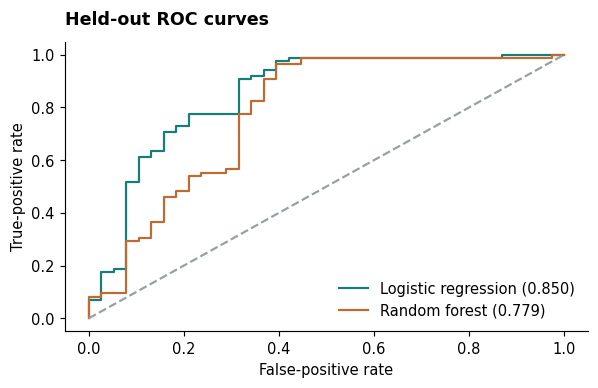

In [5]:
scores = {name: model.fit(X_train, y_train).predict_proba(X_test)[:, 1] for name, model in models.items()}
test_table = {name + " at 0.50": metrics(y_test, s, .5) for name, s in scores.items()}
test_table["Always approved"] = metrics(y_test, np.ones(len(y_test)), .5)
test_table[f"{chosen} at {threshold:.2f} (selected)"] = metrics(y_test, scores[chosen], threshold)
display(pd.DataFrame(test_table).T.round(3))
fig, ax = plt.subplots(figsize=(5.8, 3.8))
for (name, s), color in zip(scores.items(), [TEAL, AMBER]):
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, s):.3f})", color=color)
ax.plot([0,1], [0,1], "--", color="#969fa3")
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Held-out ROC curves")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

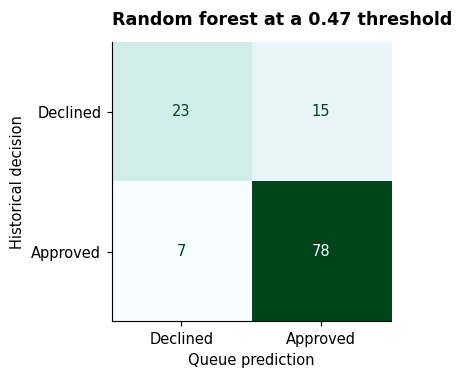

In [6]:
cm = confusion_matrix(y_test, scores[chosen] >= threshold, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(5.6, 3.7))
ConfusionMatrixDisplay(cm, display_labels=["Declined", "Approved"]).plot(ax=ax, cmap="BuGn", colorbar=False)
ax.set(xlabel="Queue prediction", ylabel="Historical decision", title=f"{chosen} at a {threshold:.2f} threshold")
plt.tight_layout()
plt.show()

In [7]:
print(f"Priority queue: {tp+fp} files ({tp} prior approvals, {fp} prior declines)")
print(f"Standard queue: {tn+fn} files ({fn} prior approvals, {tn} prior declines)")
print(f"Test cost: {2*fp+fn} units under the assumed 2:1 rule")

Priority queue: 93 files (78 prior approvals, 15 prior declines)
Standard queue: 30 files (7 prior approvals, 23 prior declines)
Test cost: 37 units under the assumed 2:1 rule


## Queue recommendation

Pilot the random forest at a score of 0.47 in a shadow review queue. It ranked first on development-fold ROC-AUC. On the 123 held-out files it would prioritize 93, of which 78 had been approved. Seven historical approvals would wait in the standard queue. Analysts would still review both queues.

Logistic regression is easier to explain and ranked applications better in the held-out sample. A larger, later batch would help determine whether that advantage persists. Before changing queue order, measure actual reviewer time and waiting costs, rerun the threshold calculation, and check error rates across applicant groups. Repayment risk requires a separate outcome dataset.